<a href="https://colab.research.google.com/github/pratyay2409/NLP/blob/Assignment/NLP_Activity_4_Problem_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Problem 3:

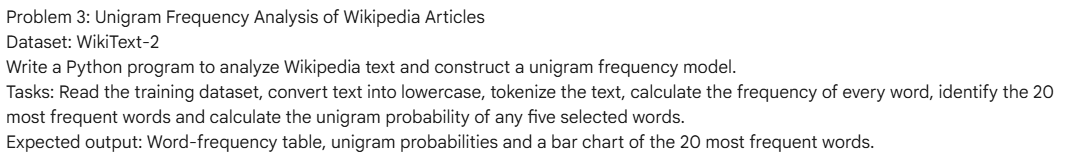

In [7]:
!pip install -q datasets matplotlib

In [10]:
# Downloads the WikiText-2 dataset (raw version), and extracts the training split for analysis.
from datasets import load_dataset, utils
from collections import Counter
import re
import matplotlib.pyplot as plt
utils.logging.disable_progress_bar()

print("Downloading and loading WikiText-2 dataset...")
dataset = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1")
train_data = dataset["train"]

print(f"Loaded {len(train_data)} rows from the training split.")

Loaded 36718 rows from the training split.


In [15]:
# Iterates through the training text, converts all characters to lowercase, tokenizes words using regular expressions (extracting alphanumeric words),
# and counts total unigram frequencies using Counter.

import string
from collections import Counter

word_counts = Counter()
total_tokens = 0

for row in train_data:
    text = row["text"]
    if not text.strip():
        continue

    # 1. Convert text to lowercase
    lower_text = text.lower()

    # 2. Normal whitespace tokenization
    raw_tokens = lower_text.split()

    # 3. Strip surrounding standard punctuation from each word token
    tokens = [token.strip(string.punctuation) for token in raw_tokens]

    # 4. Filter out any empty tokens resulting from isolated punctuation
    tokens = [token for token in tokens if token]

    word_counts.update(tokens)
    total_tokens += len(tokens)

total_unique_words = len(word_counts)
print(f"Total tokens processed (N): {total_tokens:,}")
print(f"Total unique vocabulary size (V): {total_unique_words:,}")

Total tokens processed (N): 1,756,101
Total unique vocabulary size (V): 66,281


In [16]:
# Identifies the 20 most frequent words from the unigram model and prints a structured table displaying Rank, Word, Frequency, and Unigram Probability.

top_20 = word_counts.most_common(20)

print("=== Top 20 Most Frequent Words (WikiText-2) ===\n")
header = f"{'Rank':<6} | {'Word':<15} | {'Frequency':<12} | {'Unigram Probability P(w)':<25}"
print(header)
print("-" * len(header))

for rank, (word, count) in enumerate(top_20, 1):
    prob = count / total_tokens
    print(f"{rank:<6} | {word:<15} | {count:<12,} | {prob:<25.6e}")

=== Top 20 Most Frequent Words (WikiText-2) ===

Rank   | Word            | Frequency    | Unigram Probability P(w) 
-------------------------------------------------------------------
1      | the             | 130,769      | 7.446553e-02             
2      | of              | 57,032       | 3.247649e-02             
3      | and             | 50,735       | 2.889071e-02             
4      | in              | 45,016       | 2.563406e-02             
5      | to              | 39,522       | 2.250554e-02             
6      | a               | 36,453       | 2.075792e-02             
7      | was             | 21,008       | 1.196287e-02             
8      | on              | 15,141       | 8.621941e-03             
9      | as              | 15,058       | 8.574678e-03             
10     | s               | 14,488       | 8.250095e-03             
11     | that            | 14,351       | 8.172081e-03             
12     | for             | 13,794       | 7.854901e-03             

In [24]:
# Calculates and displays the unigram probability P(w) = count(w) / N for five selected representative words (spanning frequent stopwords, common nouns, and topic words).

selected_words = ["the", "wikipedia", "history", "war", "science"]

print("=== Unigram Probability of 5 Selected Words ===\n")
print(f"{'Word':<15} | {'Count':<10} | {'Probability P(w)':<20} | {'Formula (count / N)'}")
print("-" * 75)

for word in selected_words:
    count = word_counts.get(word.lower(), 0)
    prob = count / total_tokens if total_tokens > 0 else 0.0
    # Changed from :20.6e to :20.8f to show standard decimals
    print(f"{word:<15} | {count:<10,} | {prob:<20.8f} | {count} / {total_tokens}")

=== Unigram Probability of 5 Selected Words ===

Word            | Count      | Probability P(w)     | Formula (count / N)
---------------------------------------------------------------------------
the             | 130,769    | 0.07446553           | 130769 / 1756101
wikipedia       | 30         | 0.00001708           | 30 / 1756101
history         | 809        | 0.00046068           | 809 / 1756101
war             | 1,370      | 0.00078014           | 1370 / 1756101
science         | 220        | 0.00012528           | 220 / 1756101


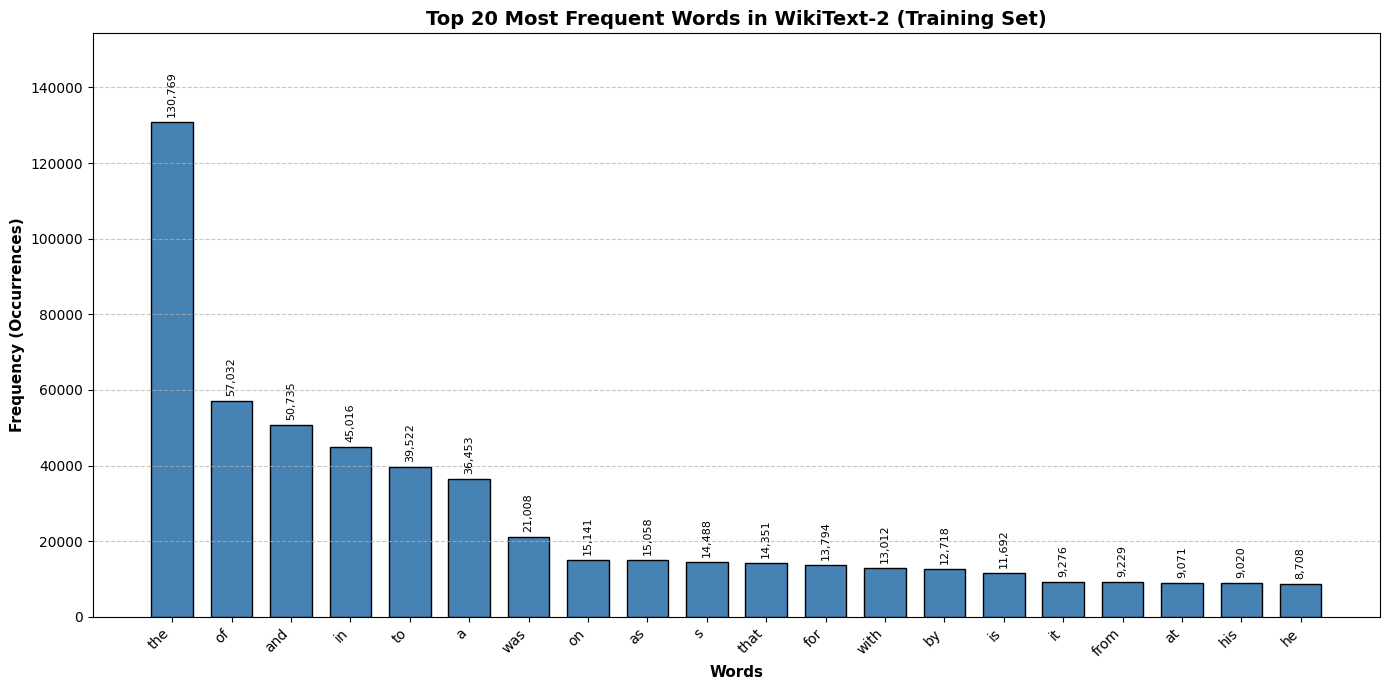

In [25]:
# Generates a clear horizontal bar chart visualizing the frequencies of the top 20 most frequent words using matplotlib.

words, frequencies = zip(*top_20)

plt.figure(figsize=(14, 7))
bars = plt.bar(words, frequencies, color="steelblue", edgecolor="black", width=0.7)

plt.title("Top 20 Most Frequent Words in WikiText-2 (Training Set)", fontsize=14, fontweight="bold")
plt.xlabel("Words", fontsize=11, fontweight="bold")
plt.ylabel("Frequency (Occurrences)", fontsize=11, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Display frequency counts directly on top of each vertical bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + (0.01 * max(frequencies)),
             f"{int(height):,}", ha="center", va="bottom", fontsize=8, rotation=90)

# Add breathing room on top of the y-axis for the text labels
plt.ylim(0, max(frequencies) * 1.18)

plt.tight_layout()
plt.show()